My project focuses on predicting solar radiation using historical weather and solar data through machine learning techniques. The predictions can support practical decision-making, such as assessing solar energy potential for household solar panel installations and assisting in solar power station planning.

I used ChatGPT as an AI-assisted tool for dashboard implementation, particularly for applying ensemble learning techniques, generating and refining code, and resolving technical issues. I reviewed and adapted the generated code to meet my project requirements.

In [2]:
!pip install pandas numpy matplotlib seaborn
!pip install scikit-learn xgboost shap joblib

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib
import shap
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
weather = pd.read_csv('weather.csv')
solar = pd.read_csv('solar.csv')

print("Weather dataset shape:", weather.shape)
print("Solar dataset shape:", solar.shape)

Weather dataset shape: (65416, 9)
Solar dataset shape: (65416, 8)


In [5]:
print("Weather columns:")
print(weather.columns.tolist())

print("\nSolar columns:")
print(solar.columns.tolist())

Weather columns:
['date', 'city', 'latitude', 'longitude', 'temp_max_c', 'temp_min_c', 'precipitation_mm', 'wind_speed_max_kmh', 'humidity_mean_pct']

Solar columns:
['date', 'city', 'latitude', 'longitude', 'radiation_kwh_m2', 'sunshine_hours', 'daylight_hours', 'uv_index_max']


In [6]:
display(weather.head())
display(solar.head())

,date,city,latitude,longitude,temp_max_c,temp_min_c,precipitation_mm,wind_speed_max_kmh,humidity_mean_pct
0,2020-01-01,Ampara,7.2975,81.6820,30.0,23.7,3.4,13.7,87
1,2020-01-01,Anuradhapura,8.3114,80.4037,30.1,23.2,1.3,14.1,87
2,2020-01-01,Badulla,6.9934,81.0550,26.7,18.7,1.6,7.2,85
3,2020-01-01,Batticaloa,7.7310,81.6747,29.6,24.6,2.9,18.0,85
4,2020-01-01,Colombo,6.9271,79.8612,29.0,24.2,1.1,11.0,88


,date,city,latitude,longitude,radiation_kwh_m2,sunshine_hours,daylight_hours,uv_index_max
0,2020-01-01,Ampara,7.2975,81.6820,4.833,11.01,11.71,NaN
1,2020-01-01,Anuradhapura,8.3114,80.4037,4.511,9.30,11.65,NaN
2,2020-01-01,Badulla,6.9934,81.0550,5.011,11.05,11.72,NaN
3,2020-01-01,Batticaloa,7.7310,81.6747,5.419,11.00,11.68,NaN
4,2020-01-01,Colombo,6.9271,79.8612,5.183,11.23,11.73,NaN


In [7]:
print(weather.info())
print(solar.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65416 entries, 0 to 65415
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   date                65416 non-null  object 
 1   city                65416 non-null  object 
 2   latitude            65416 non-null  float64
 3   longitude           65416 non-null  float64
 4   temp_max_c          65416 non-null  float64
 5   temp_min_c          65416 non-null  float64
 6   precipitation_mm    65416 non-null  float64
 7   wind_speed_max_kmh  65416 non-null  float64
 8   humidity_mean_pct   65416 non-null  int64  
dtypes: float64(6), int64(1), object(2)
memory usage: 4.5+ MB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65416 entries, 0 to 65415
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date              65416 non-null  object 
 1   city              65416 non-null

In [8]:
print("Weather missing values:")
print(weather.isnull().sum())

print("\nSolar missing values:")
print(solar.isnull().sum())

print("\nWeather duplicate rows:", weather.duplicated().sum())
print("Solar duplicate rows:", solar.duplicated().sum())

Weather missing values:
date                  0
city                  0
latitude              0
longitude             0
temp_max_c            0
temp_min_c            0
precipitation_mm      0
wind_speed_max_kmh    0
humidity_mean_pct     0
dtype: int64

Solar missing values:
date                    0
city                    0
latitude                0
longitude               0
radiation_kwh_m2        0
sunshine_hours          0
daylight_hours          0
uv_index_max        64038
dtype: int64

Weather duplicate rows: 0
Solar duplicate rows: 0


In [9]:
weather["date"] = pd.to_datetime(weather["date"])
solar["date"] = pd.to_datetime(solar["date"])

weather["city"] = weather["city"].astype(str).str.strip().str.lower()
solar["city"] = solar["city"].astype(str).str.strip().str.lower()

Check whether there are duplicate date-city combinations

In [10]:
print(weather.duplicated(["date", "city"]).sum())
print(solar.duplicated(["date", "city"]).sum())

0
0


Check matching records.
both: records that exist in both datasets.
left_only: records found only in weather.
right_only: records found only in solar.

In [11]:
keys = ["date", "city"]

matching_check = weather.merge(
    solar,
    on=keys,
    how="outer",
    indicator=True
)

print(matching_check["_merge"].value_counts())

_merge
both          65416
left_only         0
right_only        0
Name: count, dtype: int64


retains only records where the same date and city exist in both datasets. This ensures that each training record has both weather information and its corresponding solar measurement.

In [12]:
merged_data = pd.merge(
    weather,
    solar,
    on=["date", "city"],
    how="inner",
    validate="one_to_one"
)

print("Merged dataset shape:", merged_data.shape)

display(merged_data.head())

Merged dataset shape: (65416, 15)


,date,city,latitude_x,longitude_x,temp_max_c,temp_min_c,precipitation_mm,wind_speed_max_kmh,humidity_mean_pct,latitude_y,longitude_y,radiation_kwh_m2,sunshine_hours,daylight_hours,uv_index_max
0,2020-01-01,ampara,7.2975,81.6820,30.0,23.7,3.4,13.7,87,7.2975,81.6820,4.833,11.01,11.71,NaN
1,2020-01-01,anuradhapura,8.3114,80.4037,30.1,23.2,1.3,14.1,87,8.3114,80.4037,4.511,9.30,11.65,NaN
2,2020-01-01,badulla,6.9934,81.0550,26.7,18.7,1.6,7.2,85,6.9934,81.0550,5.011,11.05,11.72,NaN
3,2020-01-01,batticaloa,7.7310,81.6747,29.6,24.6,2.9,18.0,85,7.7310,81.6747,5.419,11.00,11.68,NaN
4,2020-01-01,colombo,6.9271,79.8612,29.0,24.2,1.1,11.0,88,6.9271,79.8612,5.183,11.23,11.73,NaN


In [13]:
os.makedirs("/content/drive/MyDrive/SriLanka_Solar_Ensemble/dataset",
            exist_ok=True)

merged_data.to_csv(
    "/content/drive/MyDrive/SriLanka_Solar_Ensemble/dataset/merged_solar_weather.csv",
    index=False
)

Inspect the merged dataset. Which columns contain missing values.
Whether numerical values are within reasonable ranges.
The average, minimum and maximum of numerical measurements.

In [14]:
display(merged_data.head())
print(merged_data.info())
print(merged_data.isnull().sum())
print(merged_data.describe())

,date,city,latitude_x,longitude_x,temp_max_c,temp_min_c,precipitation_mm,wind_speed_max_kmh,humidity_mean_pct,latitude_y,longitude_y,radiation_kwh_m2,sunshine_hours,daylight_hours,uv_index_max
0,2020-01-01,ampara,7.2975,81.6820,30.0,23.7,3.4,13.7,87,7.2975,81.6820,4.833,11.01,11.71,NaN
1,2020-01-01,anuradhapura,8.3114,80.4037,30.1,23.2,1.3,14.1,87,8.3114,80.4037,4.511,9.30,11.65,NaN
2,2020-01-01,badulla,6.9934,81.0550,26.7,18.7,1.6,7.2,85,6.9934,81.0550,5.011,11.05,11.72,NaN
3,2020-01-01,batticaloa,7.7310,81.6747,29.6,24.6,2.9,18.0,85,7.7310,81.6747,5.419,11.00,11.68,NaN
4,2020-01-01,colombo,6.9271,79.8612,29.0,24.2,1.1,11.0,88,6.9271,79.8612,5.183,11.23,11.73,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65416 entries, 0 to 65415
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   date                65416 non-null  datetime64[ns]
 1   city                65416 non-null  object        
 2   latitude_x          65416 non-null  float64       
 3   longitude_x         65416 non-null  float64       
 4   temp_max_c          65416 non-null  float64       
 5   temp_min_c          65416 non-null  float64       
 6   precipitation_mm    65416 non-null  float64       
 7   wind_speed_max_kmh  65416 non-null  float64       
 8   humidity_mean_pct   65416 non-null  int64         
 9   latitude_y          65416 non-null  float64       
 10  longitude_y         65416 non-null  float64       
 11  radiation_kwh_m2    65416 non-null  float64       
 12  sunshine_hours      65416 non-null  float64       
 13  daylight_hours      65416 non-null  float64   

Drop the uv_index_max column. Since the uv_index_max column has missing values and that column is not a required for prediction.

In [15]:
merged_data = merged_data.drop(
    columns=["uv_index_max"]
)

In [16]:
merged_data.to_csv(
    "/content/drive/MyDrive/SriLanka_Solar_Ensemble/dataset/merged_solar_weather.csv",
    index=False
)
print("Updated dataset successfully saved!")

Updated dataset successfully saved!


In [17]:
# Check whether latitude values are identical
latitude_match = (
    merged_data["latitude_x"].equals(merged_data["latitude_y"])
)

# Check whether longitude values are identical
longitude_match = (
    merged_data["longitude_x"].equals(merged_data["longitude_y"])
)

print("Are latitude values identical?", latitude_match)
print("Are longitude values identical?", longitude_match)

Are latitude values identical? True
Are longitude values identical? True


In [18]:
print(
    "Different latitude values:",
    (merged_data["latitude_x"] != merged_data["latitude_y"]).sum()
)

print(
    "Different longitude values:",
    (merged_data["longitude_x"] != merged_data["longitude_y"]).sum()
)

Different latitude values: 0
Different longitude values: 0


In [19]:
latitude_match = np.isclose(
    merged_data["latitude_x"],
    merged_data["latitude_y"],
    equal_nan=True
).all()

longitude_match = np.isclose(
    merged_data["longitude_x"],
    merged_data["longitude_y"],
    equal_nan=True
).all()

print("Latitude values match:", latitude_match)
print("Longitude values match:", longitude_match)

Latitude values match: True
Longitude values match: True


Latitude and longitude represent the geographical location of each city.Both datasets contain the same coordinates for the same records, keeping both pairs provides no additional information. Removing the duplicates makes the merged dataset cleaner and avoids confusion when selecting model features.

In [20]:
if latitude_match and longitude_match:

    # Keep the coordinates from the weather dataset
    merged_data = merged_data.drop(
        columns=["latitude_y", "longitude_y"]
    )

    # Rename the remaining columns
    merged_data = merged_data.rename(columns={
        "latitude_x": "latitude",
        "longitude_x": "longitude"
    })

    print("Duplicate coordinate columns removed successfully.")

else:
    print("Coordinate values are not identical. Investigate before dropping.")

Duplicate coordinate columns removed successfully.


In [21]:
print(merged_data.columns.tolist())

print("\nFinal coordinate columns:")
print(merged_data[["latitude", "longitude"]].head())

['date', 'city', 'latitude', 'longitude', 'temp_max_c', 'temp_min_c', 'precipitation_mm', 'wind_speed_max_kmh', 'humidity_mean_pct', 'radiation_kwh_m2', 'sunshine_hours', 'daylight_hours']

Final coordinate columns:
   latitude  longitude
0    7.2975    81.6820
1    8.3114    80.4037
2    6.9934    81.0550
3    7.7310    81.6747
4    6.9271    79.8612


In [22]:
merged_data.to_csv(
    "/content/drive/MyDrive/SriLanka_Solar_Ensemble/dataset/merged_solar_weather.csv",
    index=False
)
print("Successfully saved the cleaned dataset (duplicate coordinates removed)!")

Successfully saved the cleaned dataset (duplicate coordinates removed)!


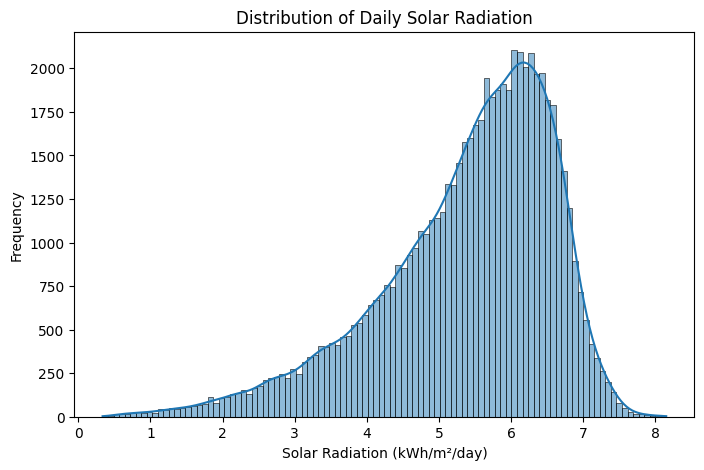

In [23]:
plt.figure(figsize=(8, 5))

sns.histplot(
    merged_data["radiation_kwh_m2"],
    kde=True
)

plt.title("Distribution of Daily Solar Radiation")
plt.xlabel("Solar Radiation (kWh/m²/day)")
plt.ylabel("Frequency")

plt.show()

understand how solar radiation differs across locations.

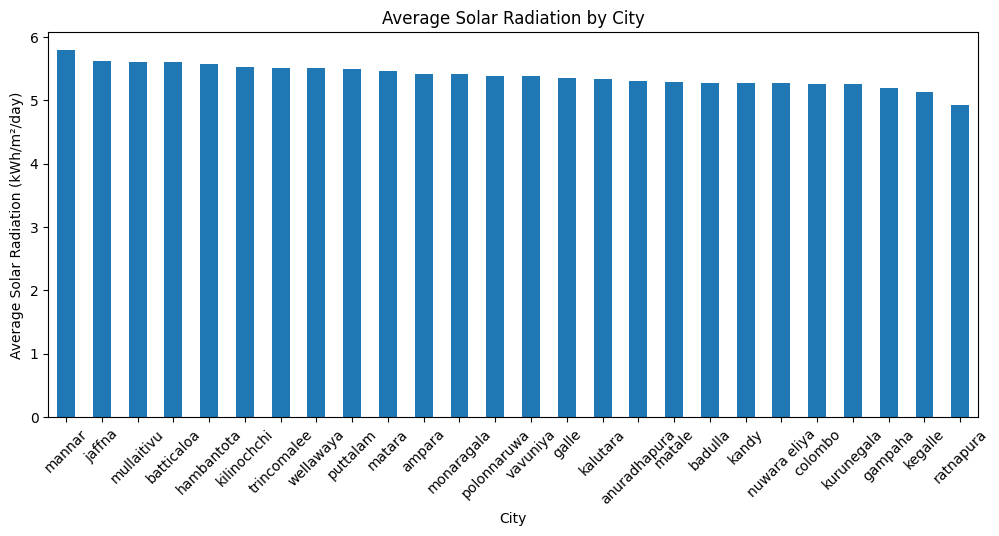

In [24]:
plt.figure(figsize=(12, 5))

city_radiation = (
    merged_data.groupby("city")["radiation_kwh_m2"]
    .mean()
    .sort_values(ascending=False)
)

city_radiation.plot(kind="bar")

plt.title("Average Solar Radiation by City")
plt.ylabel("Average Solar Radiation (kWh/m²/day)")
plt.xlabel("City")
plt.xticks(rotation=45)

plt.show()

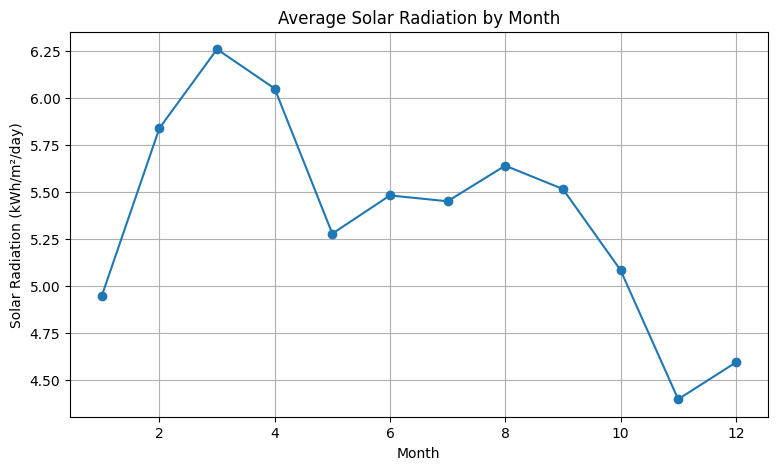

In [25]:
#identify seasonal patterns in solar radiation.
merged_data["month"] = merged_data["date"].dt.month

monthly_radiation = (
    merged_data.groupby("month")["radiation_kwh_m2"]
    .mean()
)

monthly_radiation.plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

plt.title("Average Solar Radiation by Month")
plt.xlabel("Month")
plt.ylabel("Solar Radiation (kWh/m²/day)")
plt.grid(True)

plt.show()

Correlation helps us understand how numerical variables move in relation to one another. However, correlation does not prove that one variable causes another.

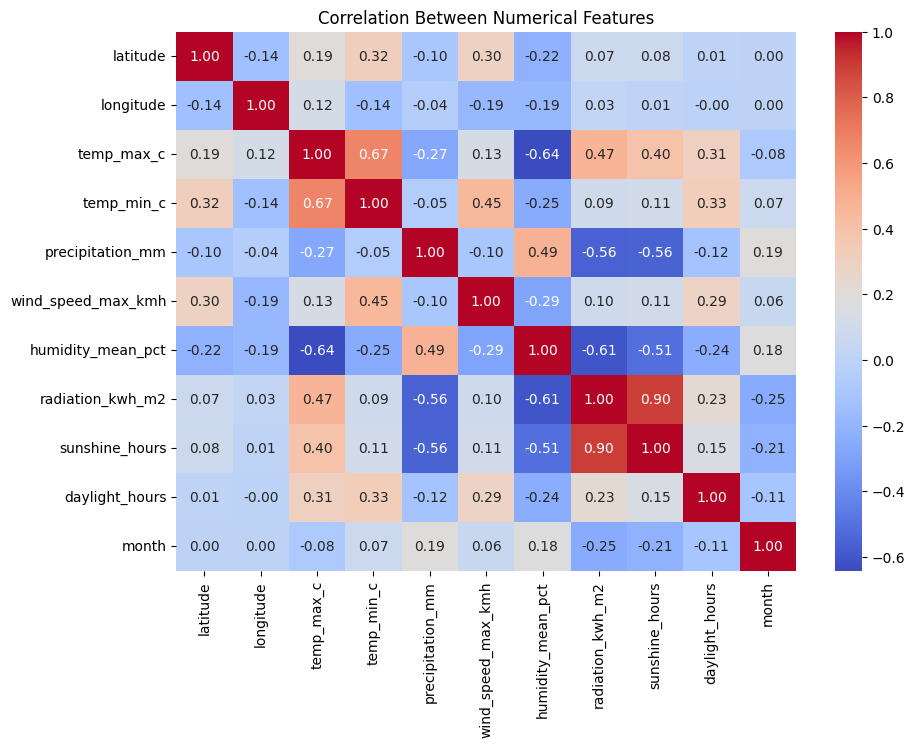

In [26]:
numeric_data = merged_data.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.show()

dataset has meaningful, physically justifiable relationships. The features carry strong predictive power for solar radiation, then model will have genuine patterns to learn from rather than random noise.

In [27]:
#date itself is not directly suitable as a numerical input for our models.
#Instead, we can extract useful information from it
merged_data["month"] = merged_data["date"].dt.month
merged_data["day_of_year"] = merged_data["date"].dt.dayofyear

In [28]:
feature_columns = [
    "temp_max_c",
    "temp_min_c",
    "precipitation_mm",
    "wind_speed_max_kmh",
    "humidity_mean_pct",
    "latitude",
    "longitude",
    "city",
    "month",
    "day_of_year"
]

target_column = "radiation_kwh_m2"

X = merged_data[feature_columns].copy()

y = merged_data[target_column].copy()

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Input features shape: (65416, 10)
Target shape: (65416,)


,temp_max_c,temp_min_c,precipitation_mm,wind_speed_max_kmh,humidity_mean_pct,latitude,longitude,city,month,day_of_year
0,30.0,23.7,3.4,13.7,87,7.2975,81.6820,ampara,1,1
1,30.1,23.2,1.3,14.1,87,8.3114,80.4037,anuradhapura,1,1
2,26.7,18.7,1.6,7.2,85,6.9934,81.0550,badulla,1,1
3,29.6,24.6,2.9,18.0,85,7.7310,81.6747,batticaloa,1,1
4,29.0,24.2,1.1,11.0,88,6.9271,79.8612,colombo,1,1


,radiation_kwh_m2
0,4.833
1,4.511
2,5.011
3,5.419
4,5.183


In [29]:
valid_target = y.notna()

X = X.loc[valid_target].copy()
y = y.loc[valid_target].copy()

# Keep the corresponding dates for chronological splitting
dates = merged_data.loc[valid_target, "date"].copy()

print("Records available for modelling:", len(X))
print("Missing target values remaining:", y.isnull().sum())

Records available for modelling: 65416
Missing target values remaining: 0


In [30]:
print("Missing values in input features:")
print(X.isnull().sum())

print("\nTotal missing input values:")
print(X.isnull().sum().sum())

Missing values in input features:
temp_max_c            0
temp_min_c            0
precipitation_mm      0
wind_speed_max_kmh    0
humidity_mean_pct     0
latitude              0
longitude             0
city                  0
month                 0
day_of_year           0
dtype: int64

Total missing input values:
0


divide the dataset into two parts:
- Training data 80%- used to teach the machine learning models.
- Testing data 20%- used to evaluate how well the models predict unseen records.
Since data contains dates, a random split is not ideal.I will use a chronological split, training on earlier dates and testing on later dates.

In [31]:
import numpy as np

unique_dates = np.sort(dates.unique())

split_index = int(len(unique_dates) * 0.80)

train_dates = unique_dates[:split_index]
test_dates = unique_dates[split_index:]

train_mask = dates.isin(train_dates)
test_mask = dates.isin(test_dates)

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

dates_train = dates.loc[train_mask].copy()
dates_test = dates.loc[test_mask].copy()

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining date range:")
print(dates_train.min(), "to", dates_train.max())

print("\nTesting date range:")
print(dates_test.min(), "to", dates_test.max())

Training records: 52312
Testing records: 13104

Training date range:
2020-01-01 00:00:00 to 2025-07-04 00:00:00

Testing date range:
2025-07-05 00:00:00 to 2026-11-20 00:00:00


In [32]:
# Data preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import clone

In [33]:
#Identify numerical and categorical features
numeric_features = [
    "temp_max_c",
    "temp_min_c",
    "precipitation_mm",
    "wind_speed_max_kmh",
    "humidity_mean_pct",
    "latitude",
    "longitude",
    "month",
    "day_of_year"
]

categorical_features = ["city"]

Median imputation fills missing numerical values using the median.
StandardScaler scales numerical values.
Most-frequent imputation fills missing city values.
OneHotEncoder converts city names into numerical representations.

In [34]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [35]:
#Import Random Forest
from sklearn.ensemble import RandomForestRegressor

In [36]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['temp_max_c', 'temp_min_c',
                                                   'precipitation_mm',
                                                   'wind_speed_max_kmh',
                                                   'humidity_mean_pct',
                                                   'latitude', 'longitude',
                                                   'month', 'day_of_year']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['city'])])),
                ('model',
                 RandomForestRegressor(n_estimators=300, n_jobs=-1,
                                       random_state=42))])

In [37]:
#Generate predictions
rf_predictions = rf_pipeline.predict(X_test)

print("Random Forest predictions:")
print(rf_predictions[:10])

Random Forest predictions:
[5.83035    6.24822333 5.97475333 6.19139    5.86965    5.64983
 5.97244667 5.74069    6.30549333 5.81288667]


In [38]:
import pandas as pd

# Create a comparison table for the first 10 records of the test set
comparison_df = pd.DataFrame({
    "Date": dates_test.iloc[:10].dt.strftime('%Y-%m-%d').values,
    "City": X_test["city"].iloc[:10].values,
    "Actual Radiation": y_test.iloc[:10].values,
    "Predicted Radiation": rf_predictions[:10],
    "Absolute Error": np.abs(y_test.iloc[:10].values - rf_predictions[:10])
})

display(comparison_df)

,Date,City,Actual Radiation,Predicted Radiation,Absolute Error
0,2025-07-05,ampara,6.319,5.830350,0.488650
1,2025-07-05,anuradhapura,6.178,6.248223,0.070223
2,2025-07-05,badulla,6.450,5.974753,0.475247
3,2025-07-05,batticaloa,6.472,6.191390,0.280610
4,2025-07-05,colombo,6.392,5.869650,0.522350
5,2025-07-05,galle,5.758,5.649830,0.108170
6,2025-07-05,gampaha,6.347,5.972447,0.374553
7,2025-07-05,hambantota,6.308,5.740690,0.567310
8,2025-07-05,jaffna,6.603,6.305493,0.297507
9,2025-07-05,kalutara,6.114,5.812887,0.301113


In [39]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Performance")
print("--------------------------")
print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R2 Score:", round(rf_r2, 4))

Random Forest Performance
--------------------------
MAE: 0.4878
RMSE: 0.6386
R2 Score: 0.7233


Metric Interpretation
MAE-Average absolute difference between actual and predicted solar radiation
RMSE-Penalizes larger prediction errors more heavily
R²-Indicates how much variation in solar radiation is explained by the model

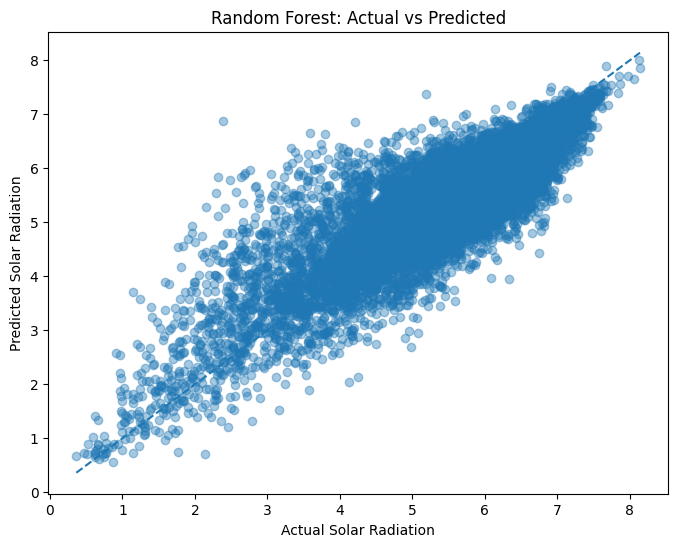

In [40]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_predictions, alpha=0.4)

min_value = min(y_test.min(), rf_predictions.min())
max_value = max(y_test.max(), rf_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Solar Radiation")
plt.ylabel("Predicted Solar Radiation")
plt.title("Random Forest: Actual vs Predicted")

plt.show()

In [41]:
#Import and train XGBoost
from xgboost import XGBRegressor

xgb_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", XGBRegressor(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['temp_max_c', 'temp_min_c',
                                                   'precipitation_mm',
                                                   'wind_speed_max_kmh',
                                                   'humidity_mean_pct',
                                                   'latitude', 'longitude',
                                                   'month', 'day_of_year']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strate...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=5, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=300, n_jobs=-1,
                              num_parallel_tree=None, ...))])

In [42]:
xgb_predictions = xgb_pipeline.predict(X_test)

print("XGBoost predictions:")
print(xgb_predictions[:10])

XGBoost predictions:
[5.9757833 6.0261664 5.991852  6.0249014 5.7922645 5.68378   5.6479006
 5.954071  6.1881437 5.7596455]


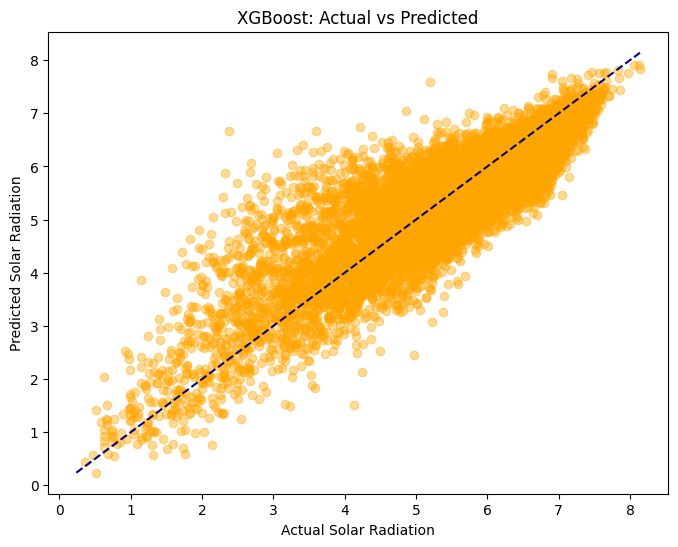

In [43]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, xgb_predictions, alpha=0.4, color="orange")

min_value = min(y_test.min(), xgb_predictions.min())
max_value = max(y_test.max(), xgb_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="navy",
    linestyle="--"
)

plt.xlabel("Actual Solar Radiation")
plt.ylabel("Predicted Solar Radiation")
plt.title("XGBoost: Actual vs Predicted")

plt.show()

In [44]:
# Compute metrics for XGBoost
xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_r2 = r2_score(y_test, xgb_predictions)

print("XGBoost Performance")
print("-------------------")
print("MAE:", round(xgb_mae, 4))
print("RMSE:", round(xgb_rmse, 4))
print("R2 Score:", round(xgb_r2, 4))

print("\nComparison with Random Forest:")
print("------------------------------")
print(f"RF MAE:  {round(rf_mae, 4)} | XGB MAE:  {round(xgb_mae, 4)}")
print(f"RF RMSE: {round(rf_rmse, 4)} | XGB RMSE: {round(xgb_rmse, 4)}")
print(f"RF R2:   {round(rf_r2, 4)} | XGB R2:   {round(xgb_r2, 4)}")

XGBoost Performance
-------------------
MAE: 0.4846
RMSE: 0.6313
R2 Score: 0.7296

Comparison with Random Forest:
------------------------------
RF MAE:  0.4878 | XGB MAE:  0.4846
RF RMSE: 0.6386 | XGB RMSE: 0.6313
RF R2:   0.7233 | XGB R2:   0.7296


XGBoost is the winning model here.

By building sequential trees that correct the mistakes of previous ones (boosting), XGBoost managed to model the subtle daily weather fluctuations in Sri Lanka slightly better than the parallel tree-bagging approach of the Random Forest. Both models, however, are highly competitive and robust baseline predictors

Our third approach is Stacking.

Stacking combines different machine learning models. Instead of simply averaging their predictions, it uses another model called a meta-learner to learn how to combine their outputs.

In [45]:
from sklearn.neural_network import MLPRegressor

mlp_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=400,
        early_stopping=True,
        random_state=42
    ))
])

In [46]:
from sklearn.linear_model import Ridge

base_models = {
    "random_forest": rf_pipeline,
    "xgboost": xgb_pipeline,
    "mlp": mlp_pipeline
}

In [47]:
from sklearn.model_selection import TimeSeriesSplit

# Reset indices to make positional indexing easier
X_train_stack = X_train.reset_index(drop=True)
y_train_stack = y_train.reset_index(drop=True)
dates_train_stack = dates_train.reset_index(drop=True)

unique_train_dates = np.sort(dates_train_stack.unique())

tscv = TimeSeriesSplit(n_splits=3)

oof_predictions = np.full(
    (len(X_train_stack), len(base_models)),
    np.nan
)

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(unique_train_dates), start=1
):

    fold_train_dates = unique_train_dates[train_idx]
    fold_val_dates = unique_train_dates[val_idx]

    fold_train_mask = dates_train_stack.isin(fold_train_dates)
    fold_val_mask = dates_train_stack.isin(fold_val_dates)

    X_fold_train = X_train_stack.loc[fold_train_mask]
    y_fold_train = y_train_stack.loc[fold_train_mask]

    X_fold_val = X_train_stack.loc[fold_val_mask]

    val_positions = np.where(fold_val_mask.to_numpy())[0]

    for model_index, (name, model) in enumerate(base_models.items()):

        fold_model = clone(model)

        fold_model.fit(X_fold_train, y_fold_train)

        fold_predictions = fold_model.predict(X_fold_val)

        oof_predictions[val_positions, model_index] = fold_predictions

    print(f"Completed stacking fold {fold}")

Completed stacking fold 1
Completed stacking fold 2
Completed stacking fold 3


In [48]:
valid_oof = ~np.isnan(oof_predictions).any(axis=1)

X_meta_train = oof_predictions[valid_oof]

y_meta_train = y_train_stack.loc[valid_oof]

meta_model = Ridge(alpha=1.0)

meta_model.fit(X_meta_train, y_meta_train)

print("Meta-learner trained successfully.")

Meta-learner trained successfully.


In [49]:
trained_base_models = {}

for name, model in base_models.items():

    final_model = clone(model)

    final_model.fit(X_train, y_train)

    trained_base_models[name] = final_model

print("All base models trained on the full training dataset.")

All base models trained on the full training dataset.


In [50]:
test_base_predictions = np.column_stack([
    trained_base_models["random_forest"].predict(X_test),
    trained_base_models["xgboost"].predict(X_test),
    trained_base_models["mlp"].predict(X_test)
])

stacking_predictions = meta_model.predict(
    test_base_predictions
)

print("Stacking predictions:")
print(stacking_predictions[:10])

Stacking predictions:
[6.05764635 6.25767176 6.44059397 6.25678707 5.98936881 5.8549122
 6.05307584 6.0598498  6.52038114 5.92504035]


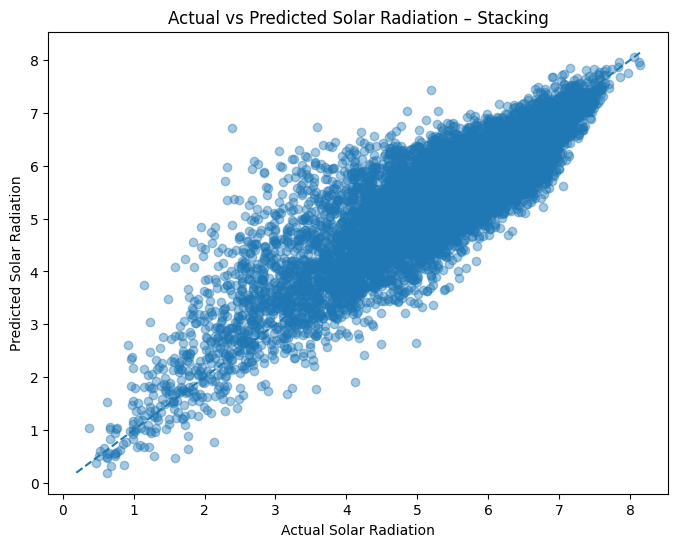

In [51]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    stacking_predictions,
    alpha=0.4
)

min_value = min(y_test.min(), stacking_predictions.min())
max_value = max(y_test.max(), stacking_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Solar Radiation")
plt.ylabel("Predicted Solar Radiation")
plt.title("Actual vs Predicted Solar Radiation – Stacking")

plt.show()

In [65]:
# Generate predictions using the trained Random Forest and ANN models
#Hybridization: Random Forest + ANN

rf_hybrid_predictions = trained_base_models["random_forest"].predict(X_test)

ann_predictions = trained_base_models["mlp"].predict(X_test)

# Assign equal weights to both models
rf_weight = 0.5
ann_weight = 0.5

# Combine predictions
hybrid_predictions = (
    rf_weight * rf_hybrid_predictions +
    ann_weight * ann_predictions
)

print("RF + ANN Hybrid predictions generated successfully.")
print("Number of hybrid predictions:", len(hybrid_predictions))

RF + ANN Hybrid predictions generated successfully.
Number of hybrid predictions: 13104


Random Forest provides predictions based on multiple decision trees.
ANN learns complex patterns through interconnected artificial neurons.
Combine their predictions using a weighted average.
Both models contribute equally to the final prediction.

In [66]:
# Calculate evaluation metrics

hybrid_mae = mean_absolute_error(y_test, hybrid_predictions)

hybrid_rmse = np.sqrt(
    mean_squared_error(y_test, hybrid_predictions)
)

hybrid_r2 = r2_score(y_test, hybrid_predictions)

# Display results
print("RF + ANN Hybrid Model Performance")
print("----------------------------------")
print(f"MAE: {hybrid_mae:.4f}")
print(f"RMSE: {hybrid_rmse:.4f}")
print(f"R2 Score: {hybrid_r2:.4f}")

RF + ANN Hybrid Model Performance
----------------------------------
MAE: 0.4581
RMSE: 0.6029
R2 Score: 0.7534


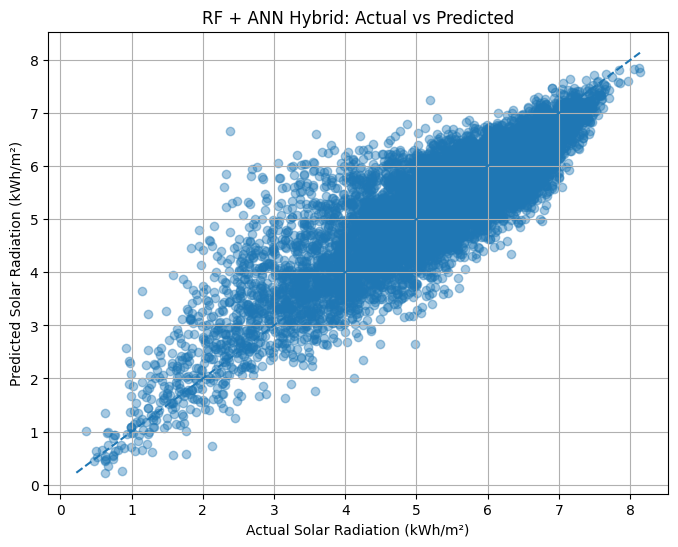

In [67]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    hybrid_predictions,
    alpha=0.4
)

min_value = min(y_test.min(), hybrid_predictions.min())
max_value = max(y_test.max(), hybrid_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Solar Radiation (kWh/m²)")
plt.ylabel("Predicted Solar Radiation (kWh/m²)")
plt.title("RF + ANN Hybrid: Actual vs Predicted")

plt.grid(True)
plt.show()

In [68]:
# Create a DataFrame containing hybrid model results

hybrid_result = pd.DataFrame([{
    "Model": "RF + ANN Hybrid",
    "MAE": hybrid_mae,
    "RMSE": hybrid_rmse,
    "R2 Score": hybrid_r2
}])

# Add hybrid results to the existing comparison table
metrics_df = pd.concat(
    [metrics_df, hybrid_result],
    ignore_index=True
)

# Display final comparison
display(metrics_df.round(4))

,Model,MAE,RMSE,R2 Score
0,Random Forest,0.4878,0.6386,0.7233
1,XGBoost,0.4846,0.6313,0.7296
2,Stacking,0.4354,0.5947,0.7601
3,RF + ANN Hybrid,0.4581,0.6029,0.7534


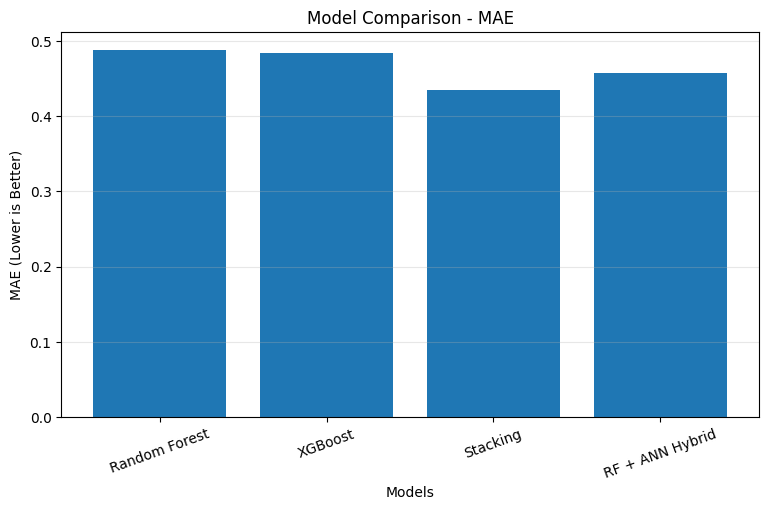

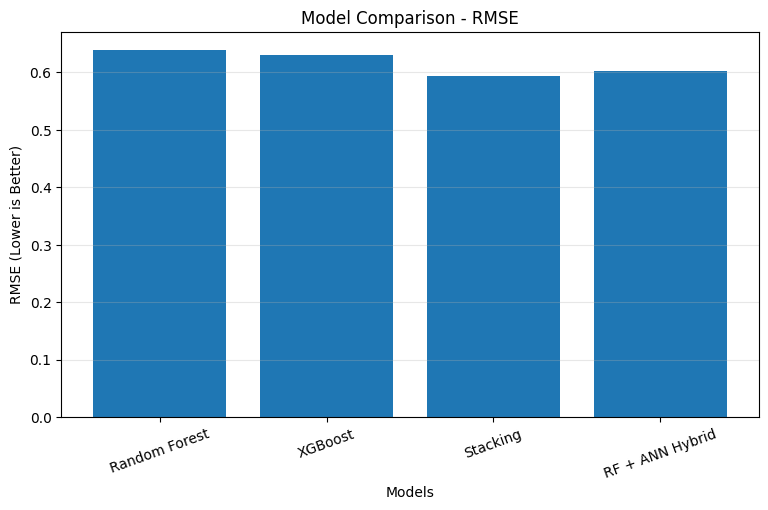

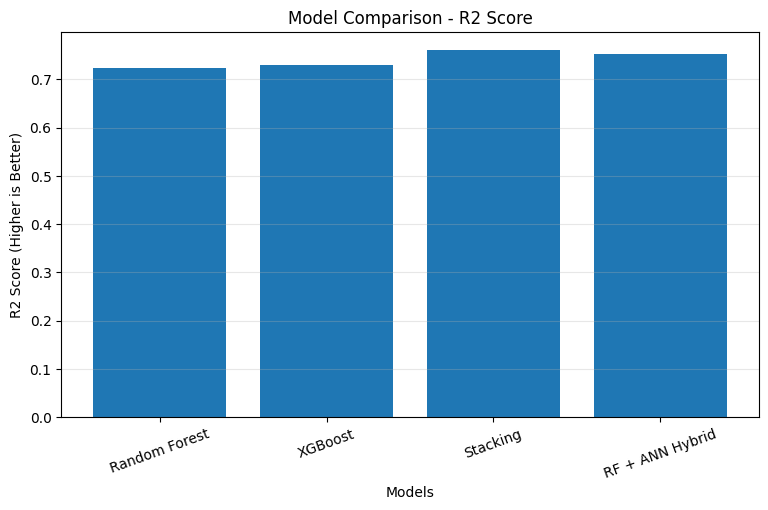

In [69]:
# Compare MAE
plt.figure(figsize=(9, 5))

plt.bar(metrics_df["Model"], metrics_df["MAE"])

plt.title("Model Comparison - MAE")
plt.xlabel("Models")
plt.ylabel("MAE (Lower is Better)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.show()


# Compare RMSE
plt.figure(figsize=(9, 5))

plt.bar(metrics_df["Model"], metrics_df["RMSE"])

plt.title("Model Comparison - RMSE")
plt.xlabel("Models")
plt.ylabel("RMSE (Lower is Better)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.show()


# Compare R2 Score
plt.figure(figsize=(9, 5))

plt.bar(metrics_df["Model"], metrics_df["R2 Score"])

plt.title("Model Comparison - R2 Score")
plt.xlabel("Models")
plt.ylabel("R2 Score (Higher is Better)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [70]:
# Identify the best model based on each metric

best_mae_model = metrics_df.loc[
    metrics_df["MAE"].idxmin()
]

best_rmse_model = metrics_df.loc[
    metrics_df["RMSE"].idxmin()
]

best_r2_model = metrics_df.loc[
    metrics_df["R2 Score"].idxmax()
]

print("Best Model Based on MAE:")
print(best_mae_model)

print("\nBest Model Based on RMSE:")
print(best_rmse_model)

print("\nBest Model Based on R2 Score:")
print(best_r2_model)

Best Model Based on MAE:
Model       Stacking
MAE         0.435363
RMSE        0.594695
R2 Score     0.76006
Name: 2, dtype: object

Best Model Based on RMSE:
Model       Stacking
MAE         0.435363
RMSE        0.594695
R2 Score     0.76006
Name: 2, dtype: object

Best Model Based on R2 Score:
Model       Stacking
MAE         0.435363
RMSE        0.594695
R2 Score     0.76006
Name: 2, dtype: object


In [73]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

predictions = {
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions,
    "Stacking": stacking_predictions,
    "RF + ANN Hybrid": hybrid_predictions
}

results = []

for model_name, model_predictions in predictions.items():

    mae = mean_absolute_error(y_test, model_predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, model_predictions)
    )

    r2 = r2_score(y_test, model_predictions)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

metrics_df = pd.DataFrame(results)

display(metrics_df.round(4))

,Model,MAE,RMSE,R2 Score
0,Random Forest,0.4878,0.6386,0.7233
1,XGBoost,0.4846,0.6313,0.7296
2,Stacking,0.4354,0.5947,0.7601
3,RF + ANN Hybrid,0.4581,0.6029,0.7534


In [74]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Actual": y_test.values,
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions,
    "Stacking": stacking_predictions,
    "RF + ANN Hybrid": hybrid_predictions

})

display(comparison_df.head(15))

,Actual,Random Forest,XGBoost,Stacking,RF + ANN Hybrid
0,6.319,5.830350,5.975783,6.057646,5.897482
1,6.178,6.248223,6.026166,6.257672,6.197639
2,6.450,5.974753,5.991852,6.440594,6.274569
3,6.472,6.191390,6.024901,6.256787,6.178521
4,6.392,5.869650,5.792264,5.989369,5.890273
5,5.758,5.649830,5.683780,5.854912,5.724507
6,6.347,5.972447,5.647901,6.053076,6.010321
7,6.308,5.740690,5.954071,6.059850,5.874678
8,6.603,6.305493,6.188144,6.520381,6.410287
9,6.114,5.812887,5.759645,5.925040,5.822691


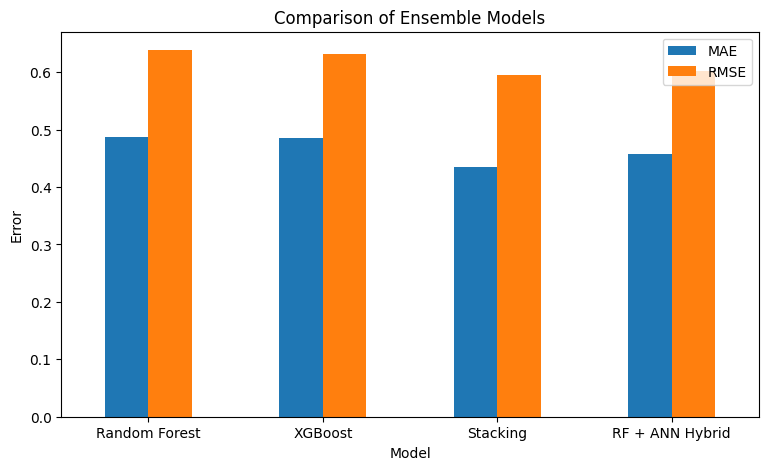

In [75]:
metrics_df.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Comparison of Ensemble Models")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.show()

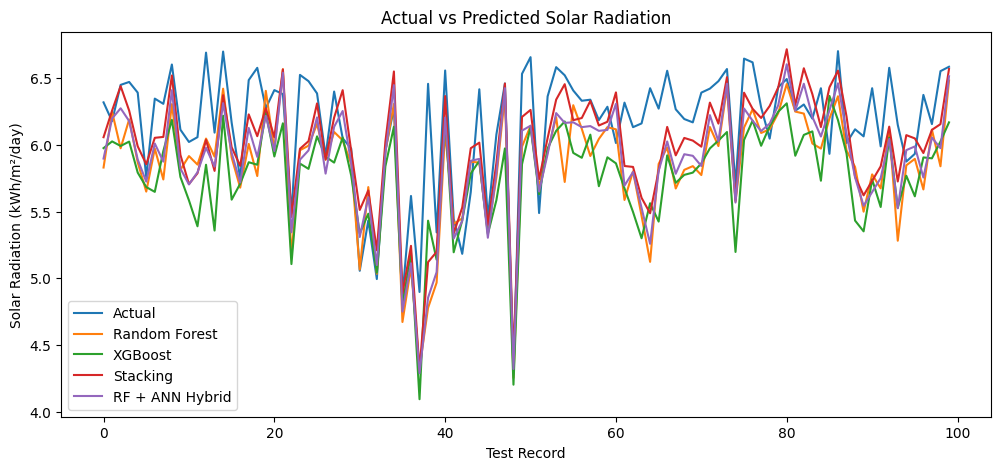

In [84]:
plt.figure(figsize=(12, 5))

plt.plot(
    comparison_df["Actual"].values[:100],
    label="Actual"
)

plt.plot(
    comparison_df["Random Forest"].values[:100],
    label="Random Forest"
)

plt.plot(
    comparison_df["XGBoost"].values[:100],
    label="XGBoost"
)

plt.plot(
    comparison_df["Stacking"].values[:100],
    label="Stacking"
)

plt.plot(
    comparison_df["RF + ANN Hybrid"].values[:100],
    label="RF + ANN Hybrid"
)

plt.title("Actual vs Predicted Solar Radiation")
plt.xlabel("Test Record")
plt.ylabel("Solar Radiation (kWh/m²/day)")
plt.legend()
plt.show()

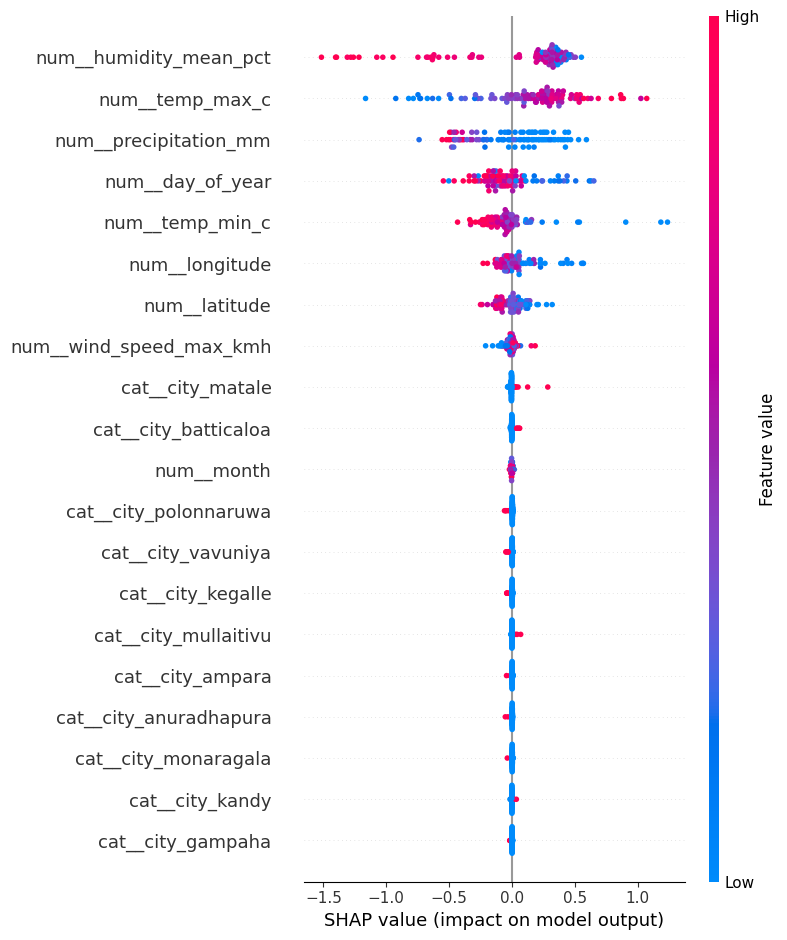

In [64]:
import shap

# Select 100 test records
X_shap = X_test.sample(
    n=min(100, len(X_test)),
    random_state=42
)

# Transform selected records
X_shap_transformed = (
    trained_base_models["random_forest"]
    .named_steps["preprocessor"]
    .transform(X_shap)
)

# Get feature names
feature_names = (
    trained_base_models["random_forest"]
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get Random Forest model
rf_model = (
    trained_base_models["random_forest"]
    .named_steps["model"]
)

# Calculate SHAP values
explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(
    X_shap_transformed
)

# Display summary plot
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names
)

### SHAP Interpretation: Feature Contributions to Solar Radiation Predictions

The SHAP (SHapley Additive exPlanations) summary plot above explains how individual weather features influence the predictions of our Random Forest model:

1. **Mean Humidity (`num__humidity_mean_pct`):** This is the most influential feature. High humidity (red dots) has a strong negative impact on solar radiation predictions, pulling down predicted values by up to $1.5\text{ kWh/m}^2$. This aligns with physics, as high humidity usually indicates cloud cover or high water vapor, blocking incoming sunlight.

2. **Maximum Temperature (`num__temp_max_c`):** Strong positive contributor. Higher maximum temperatures (red dots) correspond to significantly higher solar radiation predictions (pushing predictions up by about $0.5$ to $1.0\text{ kWh/m}^2$).

3. **Precipitation (`num__precipitation_mm`):** Any significant rainfall (red dots) immediately drives the predicted solar radiation downwards. Dry conditions (blue dots) have a slightly positive impact on the predictions.

4. **Day of the Year (`num__day_of_year`):** This capture seasonal fluctuations. Depending on the time of the year (representing monsoon or dry seasons in Sri Lanka), it can shift the prediction moderately in either direction.

5. **Geographical Features (`latitude`, `longitude` & `city`):** The geographical features have a localized, relatively minor, but consistent impact, fine-tuning the model predictions based on the microclimates of the specific cities in Sri Lanka.

In [77]:
import os
import joblib

# Create folders to store models and results
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("Folders created successfully.")

Folders created successfully.


In [78]:
# Save Random Forest model
joblib.dump(
    trained_base_models["random_forest"],
    "models/random_forest.pkl"
)

# Save XGBoost model
joblib.dump(
    trained_base_models["xgboost"],
    "models/xgboost.pkl"
)

print("Random Forest and XGBoost models saved.")

Random Forest and XGBoost models saved.


In [79]:
stacking_model = {
    "base_models": trained_base_models,
    "meta_model": meta_model
}

joblib.dump(
    stacking_model,
    "models/stacking_model.pkl"
)

print("Stacking model saved successfully.")

Stacking model saved successfully.


In [80]:
hybrid_model = {
    "random_forest": trained_base_models["random_forest"],
    "ann": trained_base_models["mlp"],
    "rf_weight": rf_weight,
    "ann_weight": ann_weight
}

joblib.dump(
    hybrid_model,
    "models/hybrid_model.pkl"
)

print("Hybrid model saved successfully.")

Hybrid model saved successfully.


In [81]:
metrics_df.to_csv(
    "results/model_metrics.csv",
    index=False
)

print("Model performance metrics saved.")

Model performance metrics saved.


In [82]:
test_results = pd.DataFrame({
    "date": dates_test.values,
    "city": X_test["city"].values,
    "actual_radiation": y_test.values,
    "random_forest_prediction": rf_predictions,
    "xgboost_prediction": xgb_predictions,
    "stacking_prediction": stacking_predictions,
    "hybrid_prediction": hybrid_predictions
})

test_results.to_csv(
    "results/test_predictions.csv",
    index=False
)

print("Test predictions saved successfully.")

Test predictions saved successfully.


In [83]:
print("SAVED MODEL FILES")
print("-----------------")

for file in os.listdir("models"):
    print(file)

print("\nSAVED RESULT FILES")
print("------------------")

for file in os.listdir("results"):
    print(file)

SAVED MODEL FILES
-----------------
random_forest.pkl
stacking_model.pkl
xgboost.pkl
hybrid_model.pkl

SAVED RESULT FILES
------------------
test_predictions.csv
model_metrics.csv


In [85]:
import os
import zipfile

# Create a ZIP containing the models, results and original datasets
zip_path = "/content/SriLanka_Solar_Artifacts.zip"

folders_to_include = ["models", "results"]
files_to_include = ["weather.csv", "solar.csv"]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:

    for folder in folders_to_include:
        for root, dirs, files in os.walk(folder):
            for file in files:
                file_path = os.path.join(root, file)
                zipf.write(file_path, file_path)

    for file in files_to_include:
        if os.path.exists(file):
            zipf.write(file, file)

print("ZIP file created successfully:", zip_path)

ZIP file created successfully: /content/SriLanka_Solar_Artifacts.zip


In [86]:
from google.colab import files

files.download("/content/SriLanka_Solar_Artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>